# Week 8 · Networks

1,478 posts from one MOOC discussion forum. 311 people.

Run the cell below.

In [1]:
%matplotlib inline
import pandas as pd, networkx as nx, matplotlib.pyplot as plt, numpy as np, itertools
from sklearn.metrics import adjusted_mutual_info_score

BASE = "https://raw.githubusercontent.com/HakeoungLee/edis8100-datasets/main/edx-mooc-forum"
posts = pd.read_csv(f"{BASE}/posts.csv")
author_of = dict(zip(posts.post_id, posts.author))

print(f"{len(posts):,} posts | {posts.author.nunique()} people | {posts.category_name.nunique()} categories")
display(posts[["author", "category_name", "parent_post_id", "title"]].head(5))

# Author ids are long hashes. Give everyone a short label so the pictures can be read.
NAME = {a: f"P{i+1:03d}" for i, a in enumerate(sorted(posts.author.dropna().unique()))}


1,478 posts | 311 people | 124 categories


,author,category_name,parent_post_id,title
0,d96db92845537eddb7c559e8de578ed12b075cad4c390a...,Week 1 / Execution Errors in Codeboard (non gr...,571f77b5d11155053000028c,NaN
1,4803b5fbbb47bd749a46cb2f873b3746e2ae6ff30a0a94...,Week 0 / 0 Introductions,NaN,INTRODUCING MYSELF..
2,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,571f715f7e622b05750002ae,NaN
3,f4f5300843bfd2c87a3248e731e6ec9c183e1b0eca545f...,Week 0 / 0 Introductions,NaN,Hii
4,d3e3caaf58986db9aa1cefc296f77a279b4a2e80e9eeed...,Week 0 / 0 Introductions,NaN,Welcome all


## 1. One network

Nothing in this file says who is connected to whom. It is a list of posts. You decide when two people count as tied, and that decision is the rule.

**A and B are tied if one replied to a post by the other.**

In the picture, **degree** is how many people someone is tied to.

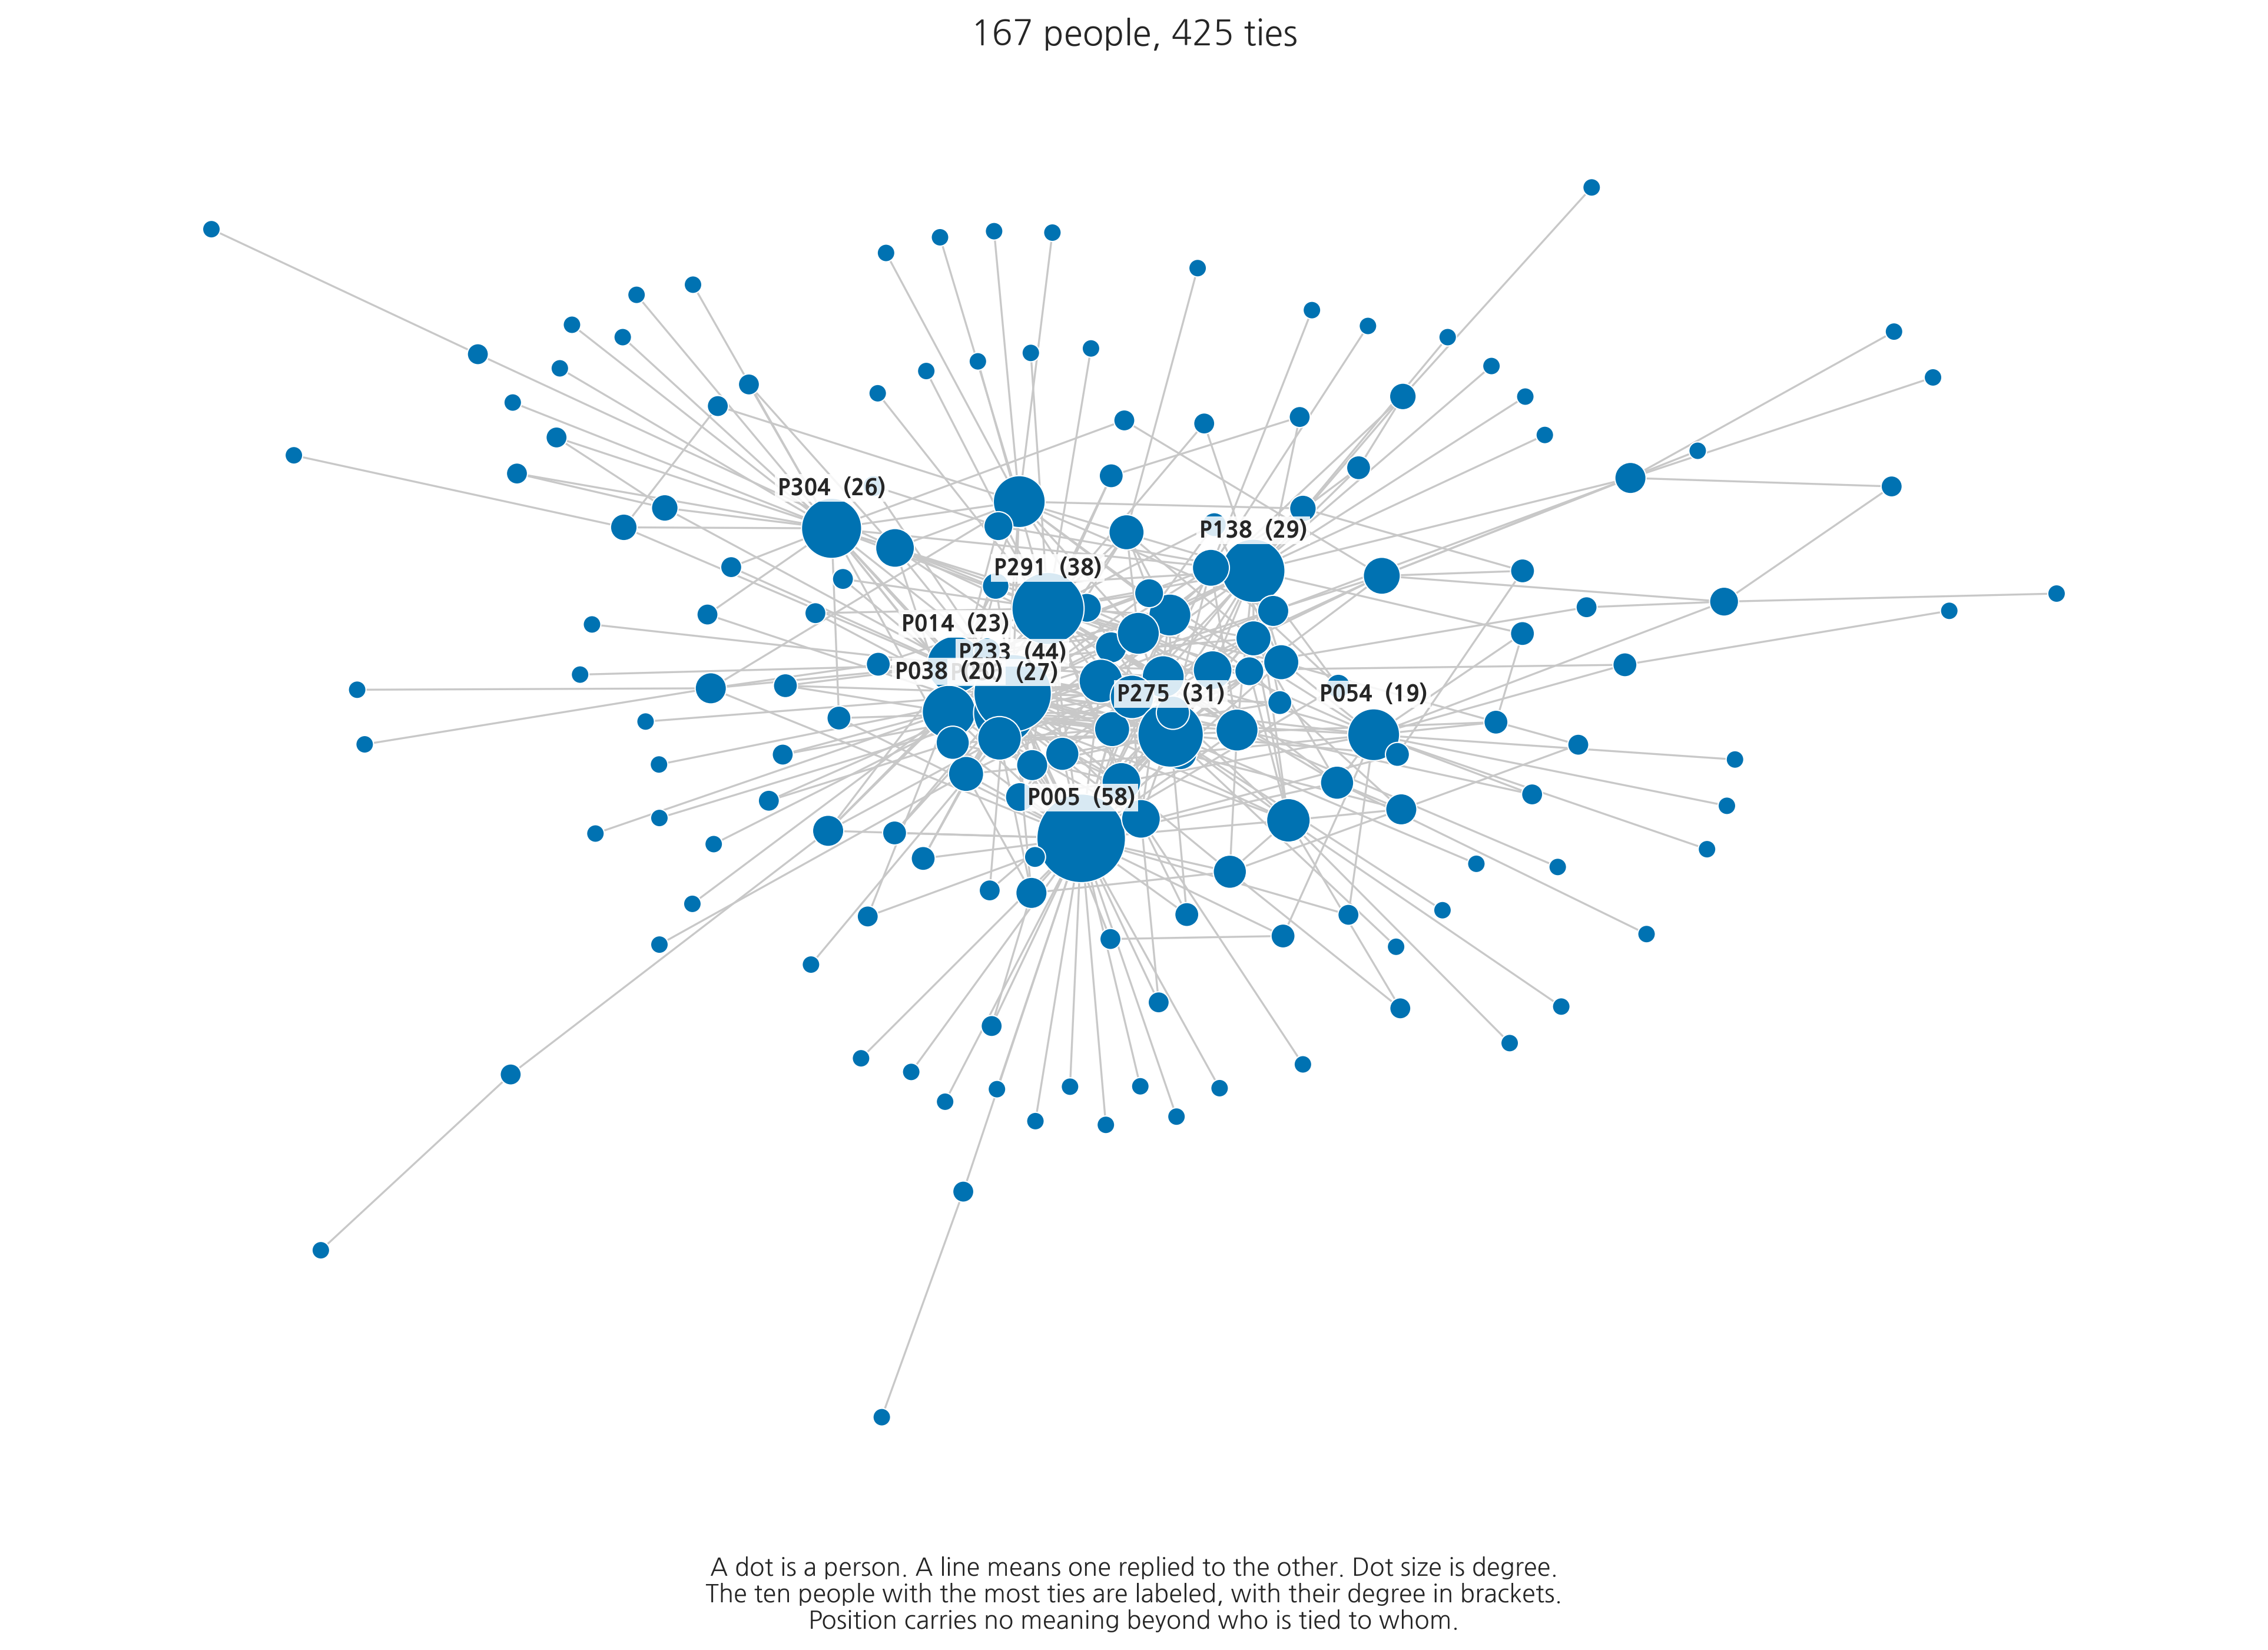

181 people made at least one tie. 130 posted and made none, so they are not here.
Degree runs from 58 down to 1. Half of them are tied to 2 people or fewer.


In [2]:
def reply_network(df):
    G = nx.Graph()
    for _, r in df.dropna(subset=["parent_post_id"]).iterrows():
        target = author_of.get(r.parent_post_id)
        if target and target != r.author:
            G.add_edge(r.author, target)
    return G

G = reply_network(posts)
LCC = G.subgraph(max(nx.connected_components(G), key=len)).copy()
pos = nx.spring_layout(LCC, seed=8100, k=0.55, iterations=300)
deg = dict(LCC.degree())
top10 = sorted(deg, key=deg.get, reverse=True)[:10]

fig, ax = plt.subplots(figsize=(13, 9.5))
nx.draw_networkx_edges(LCC, pos, ax=ax, edge_color="#c8c8c8", width=0.8)
nx.draw_networkx_nodes(LCC, pos, ax=ax, node_color="#0072b2",
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
for n in top10:
    x, y = pos[n]
    ax.annotate(f"{NAME[n]}  ({deg[n]})", (x, y), fontsize=9, fontweight="bold",
                textcoords="offset points", xytext=(0, 14), ha="center",
                bbox=dict(facecolor="white", alpha=.85, edgecolor="none", pad=1.2))

ax.set_title(f"{LCC.number_of_nodes()} people, {LCC.number_of_edges()} ties", fontsize=14)
ax.set_xlabel("A dot is a person. A line means one replied to the other. Dot size is degree.\n"
              "The ten people with the most ties are labeled, with their degree in brackets.\n"
              "Position carries no meaning beyond who is tied to whom.", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

print(f"{G.number_of_nodes()} people made at least one tie. "
      f"{posts.author.nunique() - G.number_of_nodes()} posted and made none, so they are not here.")
print(f"Degree runs from {max(deg.values())} down to {min(deg.values())}. "
      f"Half of them are tied to {int(np.median(list(deg.values())))} people or fewer.")

**Takeaway**

- 130 of the 311 people posted and made no tie at all. A network drops everyone who never replied and never got a reply, and it does it silently.
- Degree runs from 58 down to 1, and half the people are tied to 2 or fewer. A network can be almost entirely one person's ties.
- Position on the page means nothing. Only who is joined to whom does.

**Look at the picture.**

- The labeled ten against everyone else. How much of the forum is tied to how few people?
- The dots on the outside, each hanging off one line. What did those people do?
- Does the middle look like one group or several?

## 2. The same people, a different rule

A rule has two parts: what counts as a node, and what counts as a tie. Below the nodes stay the same, the people who posted, and only the tie changes.

- replied to one of their posts
- posted in the same thread
- posted in the same category

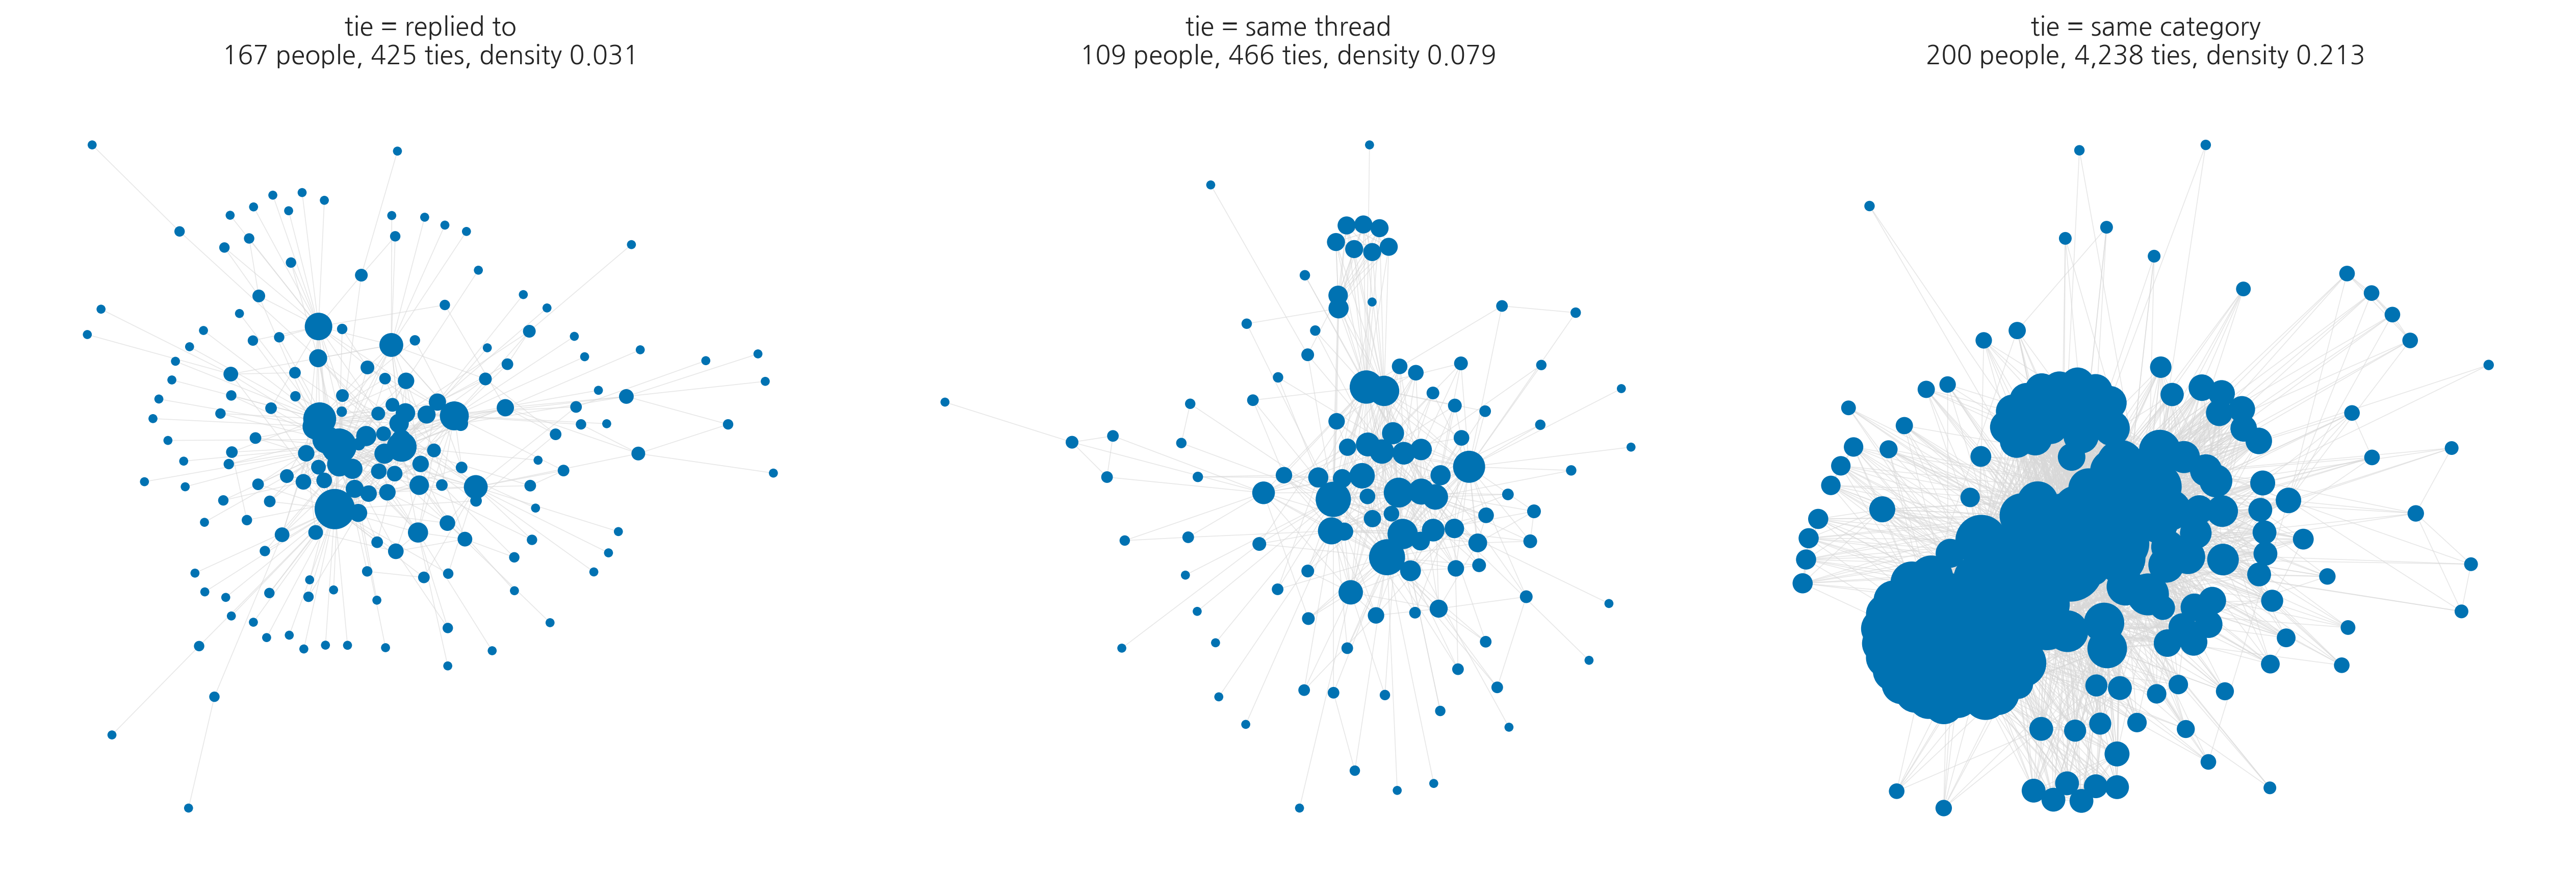

In [3]:
# A rule has two parts: what counts as a node, and what counts as a tie.
# Here the nodes are always the people who posted. Only the tie changes.

def tie_by_reply(df):
    "tie two people if one replied to the other"
    G = nx.Graph()
    for _, r in df.dropna(subset=["parent_post_id"]).iterrows():
        t = author_of.get(r.parent_post_id)
        if t and t != r.author:
            G.add_edge(r.author, t)
    return G

def tie_by_sharing(df, column, cap=120):
    "tie two people if they both posted under the same value of this column"
    G = nx.Graph()
    for _, g in df.groupby(column):
        people = sorted(set(g.author.dropna()))
        if len(people) <= cap:
            G.add_edges_from(itertools.combinations(people, 2))
    return G


nets = {
    "replied to":      tie_by_reply(posts),
    "same thread":     tie_by_sharing(posts, "thread_id"),
    "same category":   tie_by_sharing(posts, "category_name"),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, H) in zip(axes, nets.items()):
    K = H.subgraph(max(nx.connected_components(H), key=len)).copy()
    p = nx.spring_layout(K, seed=8100, k=0.5, iterations=200)
    d = dict(K.degree())
    nx.draw_networkx_edges(K, p, ax=ax, edge_color="#d8d8d8", width=0.4, alpha=.6)
    nx.draw_networkx_nodes(K, p, ax=ax, node_color="#0072b2",
                           node_size=[12 + 6 * d[n] for n in K.nodes()], linewidths=0)
    ax.set_title(f"tie = {name}\n{K.number_of_nodes()} people, {K.number_of_edges():,} ties, "
                 f"density {nx.density(K):.3f}", fontsize=12)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Takeaway**

- Same 1,478 posts, three rules, three different networks. Density runs from 0.03 to 0.21.
- No rule is the right one. Replying to someone and posting in the same category are different claims about what connects two people.
- The rule is a research decision, and it is made before any measure is computed.

Same posts, same people. Only the tie changed.

Which of the three would you use, and for what question?

## 3. Communities

A **community** is a set of people tied to each other more than to the rest of the network. The algorithm finds them from the ties alone, and it will return communities from any network, including one with ties drawn at random.

In the picture: are the labeled people in the middle of their own color, or on the edge of it? And is there a color that barely touches the others?

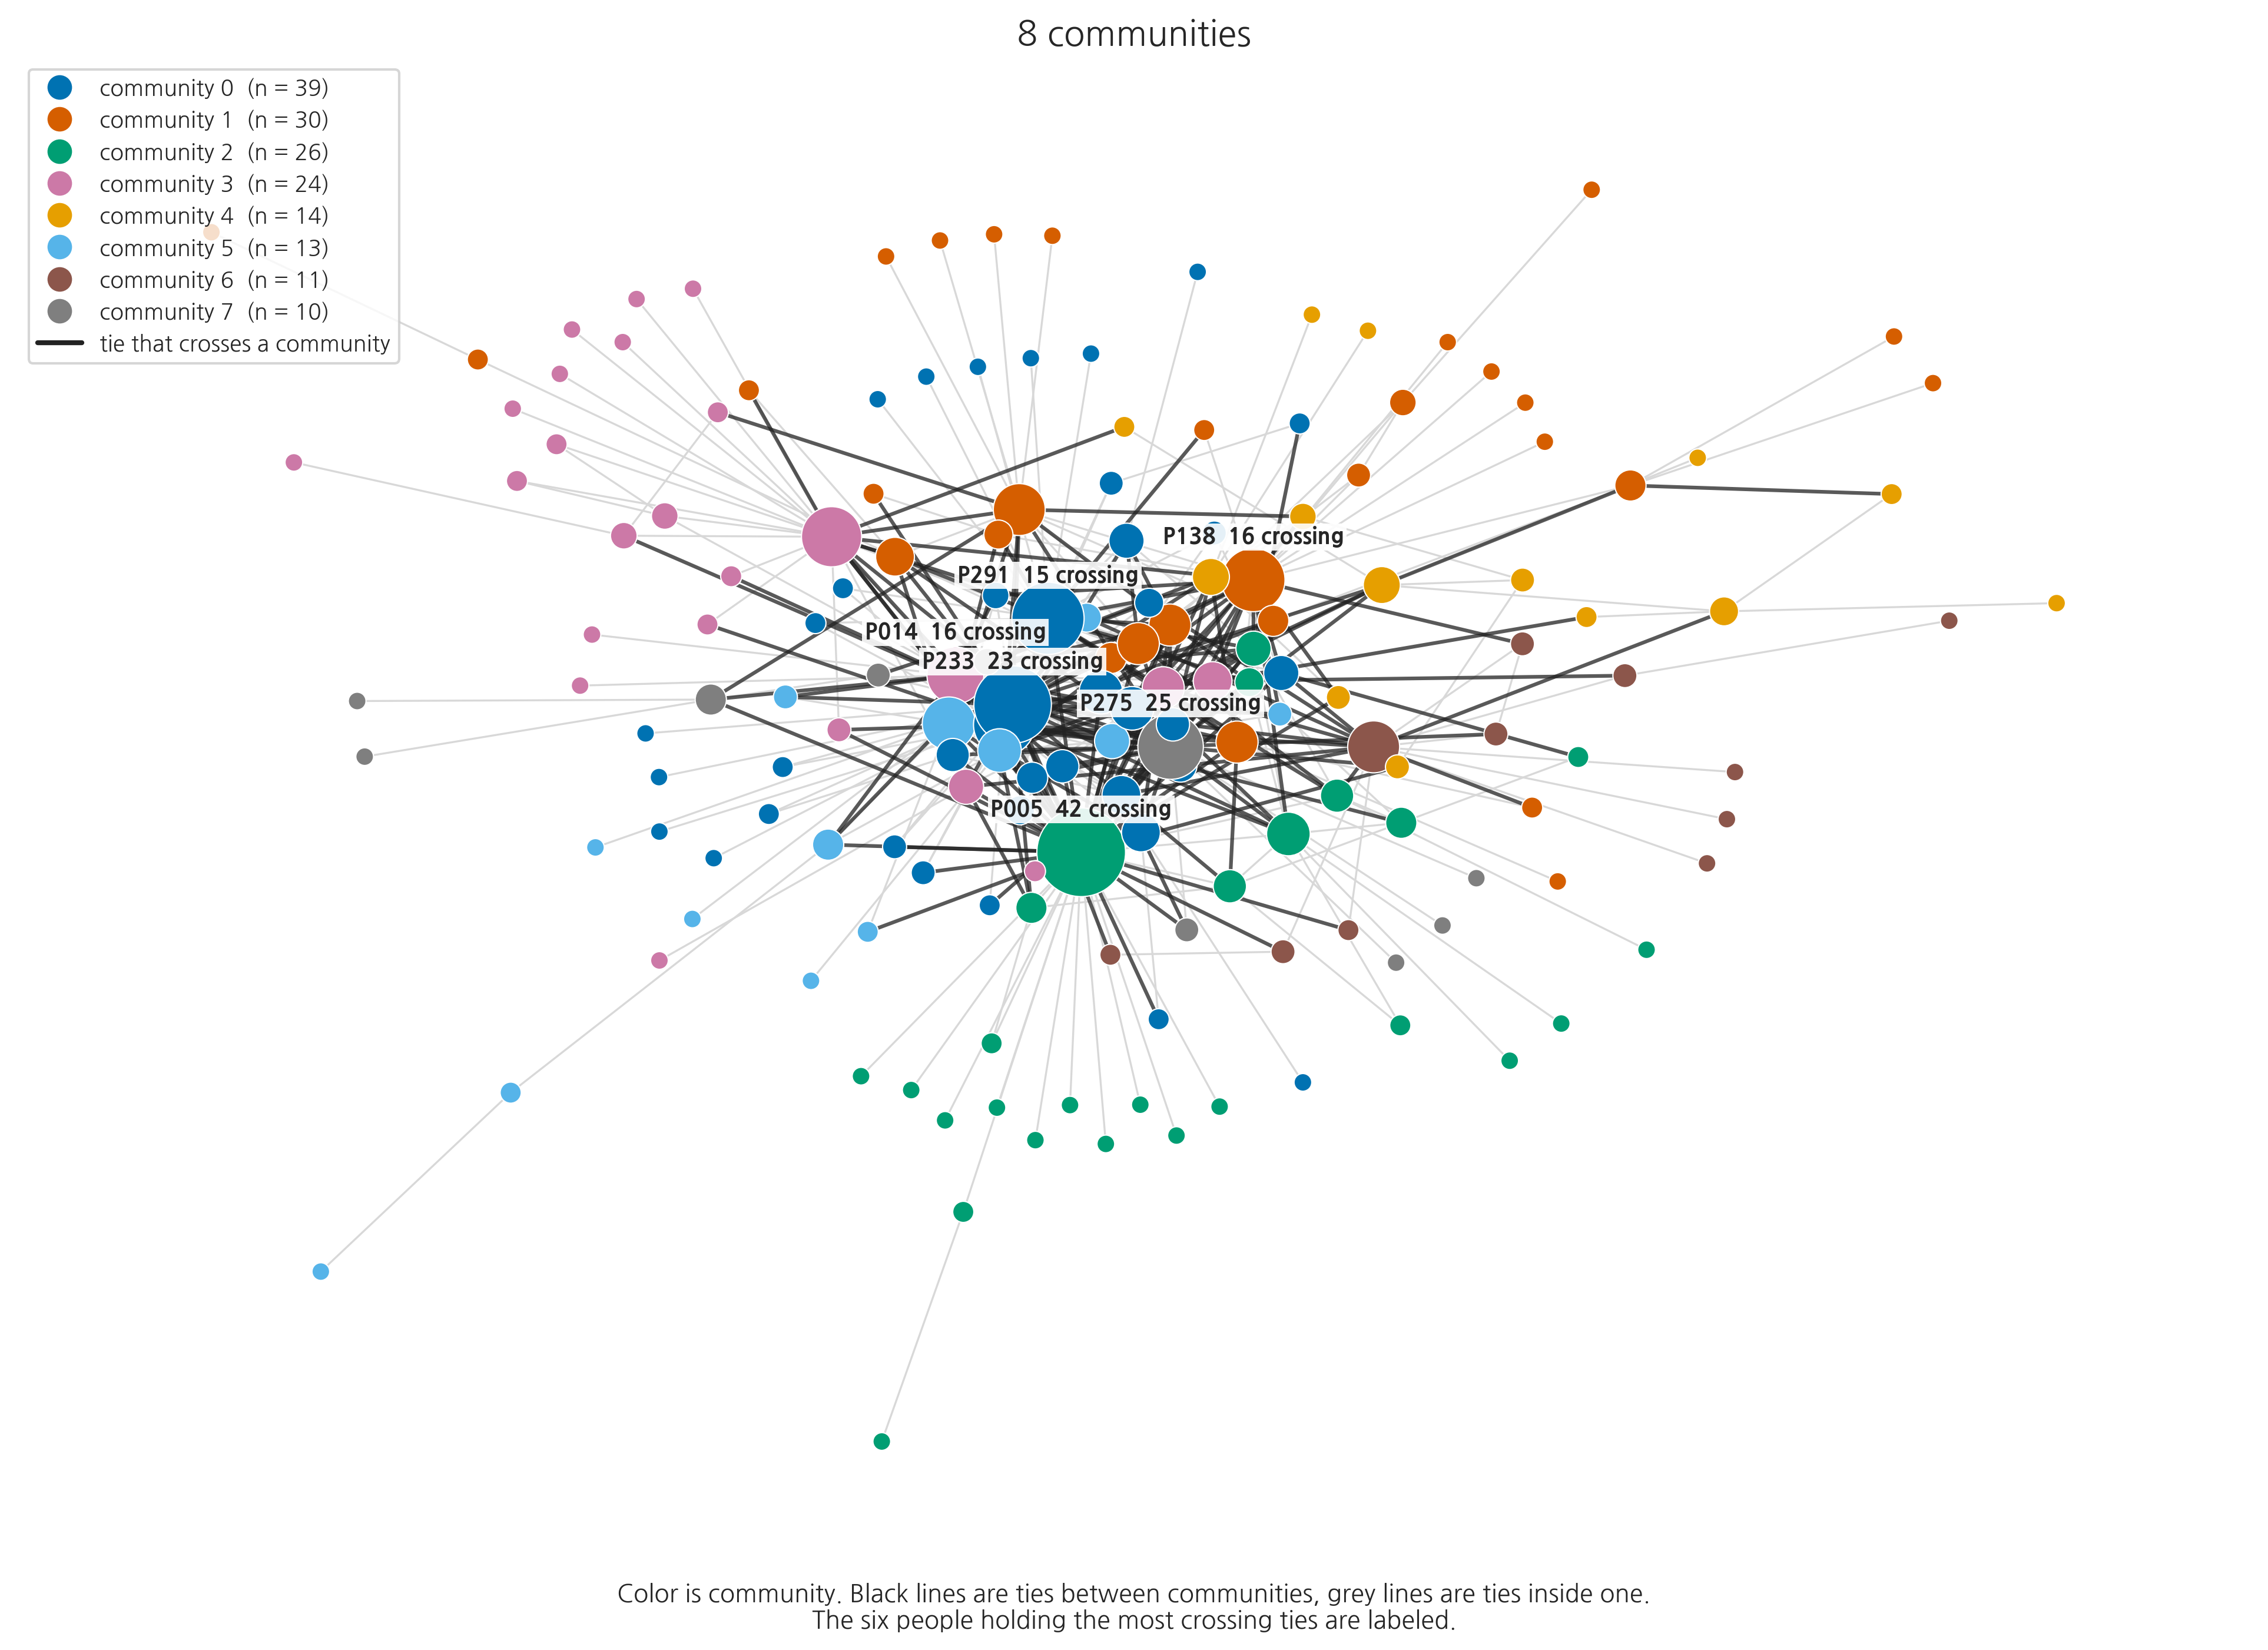

community sizes: [39, 30, 26, 24, 14, 13, 11, 10]
199 of 425 ties cross a community line.


In [4]:
communities = list(nx.community.greedy_modularity_communities(LCC))
community_of = {n: i for i, c_ in enumerate(communities) for n in c_}
COLORS = ["#0072b2", "#d55e00", "#009e73", "#cc79a7", "#e69f00", "#56b4e9", "#8c564b", "#7f7f7f"]

within = [(a, b) for a, b in LCC.edges() if community_of[a] == community_of[b]]
across  = [(a, b) for a, b in LCC.edges() if community_of[a] != community_of[b]]

# who holds the most ties that leave their own community
crossing = pd.Series(0, index=list(LCC.nodes()))
for a, b in across:
    crossing[a] += 1; crossing[b] += 1
bridges = crossing.nlargest(6).index.tolist()

fig, ax = plt.subplots(figsize=(13, 9.5))
nx.draw_networkx_edges(LCC, pos, edgelist=within, ax=ax, edge_color="#d8d8d8", width=0.8)
nx.draw_networkx_edges(LCC, pos, edgelist=across, ax=ax, edge_color="#222222", width=1.5, alpha=.75)
nx.draw_networkx_nodes(LCC, pos, ax=ax,
                       node_color=[COLORS[community_of[n] % len(COLORS)] for n in LCC.nodes()],
                       node_size=[30 + 22 * deg[n] for n in LCC.nodes()],
                       edgecolors="white", linewidths=0.5)
for n in bridges:
    x, y = pos[n]
    ax.annotate(f"{NAME[n]}  {crossing[n]} crossing", (x, y), fontsize=9, fontweight="bold",
                textcoords="offset points", xytext=(0, 15), ha="center",
                bbox=dict(facecolor="white", alpha=.9, edgecolor="none", pad=1.2))

handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=COLORS[i % len(COLORS)],
                      label=f"community {i}  (n = {len(c_)})") for i, c_ in enumerate(communities)]
handles.append(plt.Line2D([], [], color="#222222", lw=2, label="tie that crosses a community"))
ax.legend(handles=handles, fontsize=9, loc="upper left", frameon=True)

ax.set_title(f"{len(communities)} communities", fontsize=14)
ax.set_xlabel("Color is community. Black lines are ties between communities, grey lines are ties inside one.\n"
              "The six people holding the most crossing ties are labeled.", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

print("community sizes:", [len(c_) for c_ in communities])
print(f"{len(across)} of {LCC.number_of_edges()} ties cross a community line.")

**Takeaway**

- 199 of the 425 ties cross a community line, so the communities are not separate groups.
- The algorithm returns communities from any network, including one with ties drawn at random. Getting eight of them is not a finding.
- The people holding the most crossing ties are near the middle, not between two colors where you would expect a bridge.

## 4. Are the communities topics?

The forum has categories. If the communities are topics, people in one community should post mostly in one category.

Read the table. Pick the community with the cleanest match and the one with the worst, and decide what you would call each of them.

In [5]:
main_category = (posts.groupby(["author", "category_name"]).size().reset_index(name="n")
                 .sort_values("n", ascending=False).drop_duplicates("author")
                 .set_index("author").category_name.to_dict())

rows = []
for i, c in enumerate(communities):
    cats = pd.Series([main_category[n] for n in c if n in main_category]).value_counts()
    rows.append({"community": i, "people": len(c),
                 "most common category": cats.index[0],
                 "how many of them": f"{cats.iloc[0]} of {cats.sum()}"})
display(pd.DataFrame(rows))

nodes = [n for n in LCC.nodes() if n in main_category]
score = adjusted_mutual_info_score([community_of[n] for n in nodes],
                                   [main_category[n] for n in nodes])
print(f"\nAgreement between communities and categories: {score:.3f}")
print("(0 is what you get from unrelated groupings, 1 is a perfect match.)")

,community,people,most common category,how many of them
0,0,39,Week 2 / Exam 2,4 of 39
1,1,30,Week 0 / 0 Introductions,6 of 25
2,2,26,Week 0 / 0 Introductions,6 of 26
3,3,24,Any Question? / General,12 of 24
4,4,14,Any Questions? / Technical Help,3 of 13
5,5,13,Week 0 / 0 Introductions,4 of 13
6,6,11,Any Question? / General,3 of 11
7,7,10,Week 2 / Reasoning II (non graded activity),2 of 10



Agreement between communities and categories: 0.070
(0 is what you get from unrelated groupings, 1 is a perfect match.)


**Takeaway**

- Agreement between the communities and the forum categories is 0.07, where 0 is what unrelated groupings give you.
- So the communities are not topics. Whatever grouped these people, it was not what they were talking about.
- The algorithm named nothing. Any name on a community is one you supplied.

## 5. Does the network tell you anything a post count did not?

Poquet and Joksimovic (2022) write that centrality in online learner interaction is often a proxy for how active someone was rather than for their position among others.

Rank everyone twice, by degree and by posts written, and look at who moves.

The top 10 by degree, and where a post count would have put them:


,degree,posts written,rank by degree,rank by posts,moved
0,58.0,132,1,1,0
1,44.0,89,2,2,0
2,38.0,57,3,4,1
3,31.0,82,4,3,-1
4,29.0,48,5,6,1
5,27.0,56,6,5,-1
6,26.0,33,7,8,1
7,23.0,25,8,9,1
8,20.0,40,9,7,-2
9,19.0,19,10,13,3



The people who move most:


,degree,posts written,rank by degree,rank by posts,moved
0,3.0,1,57,119,62
1,2.0,1,74,119,45
2,2.0,1,74,119,45
3,2.0,1,74,119,45
4,2.0,1,74,119,45
5,2.0,1,74,119,45
6,2.0,1,74,119,45
7,2.0,1,74,119,45


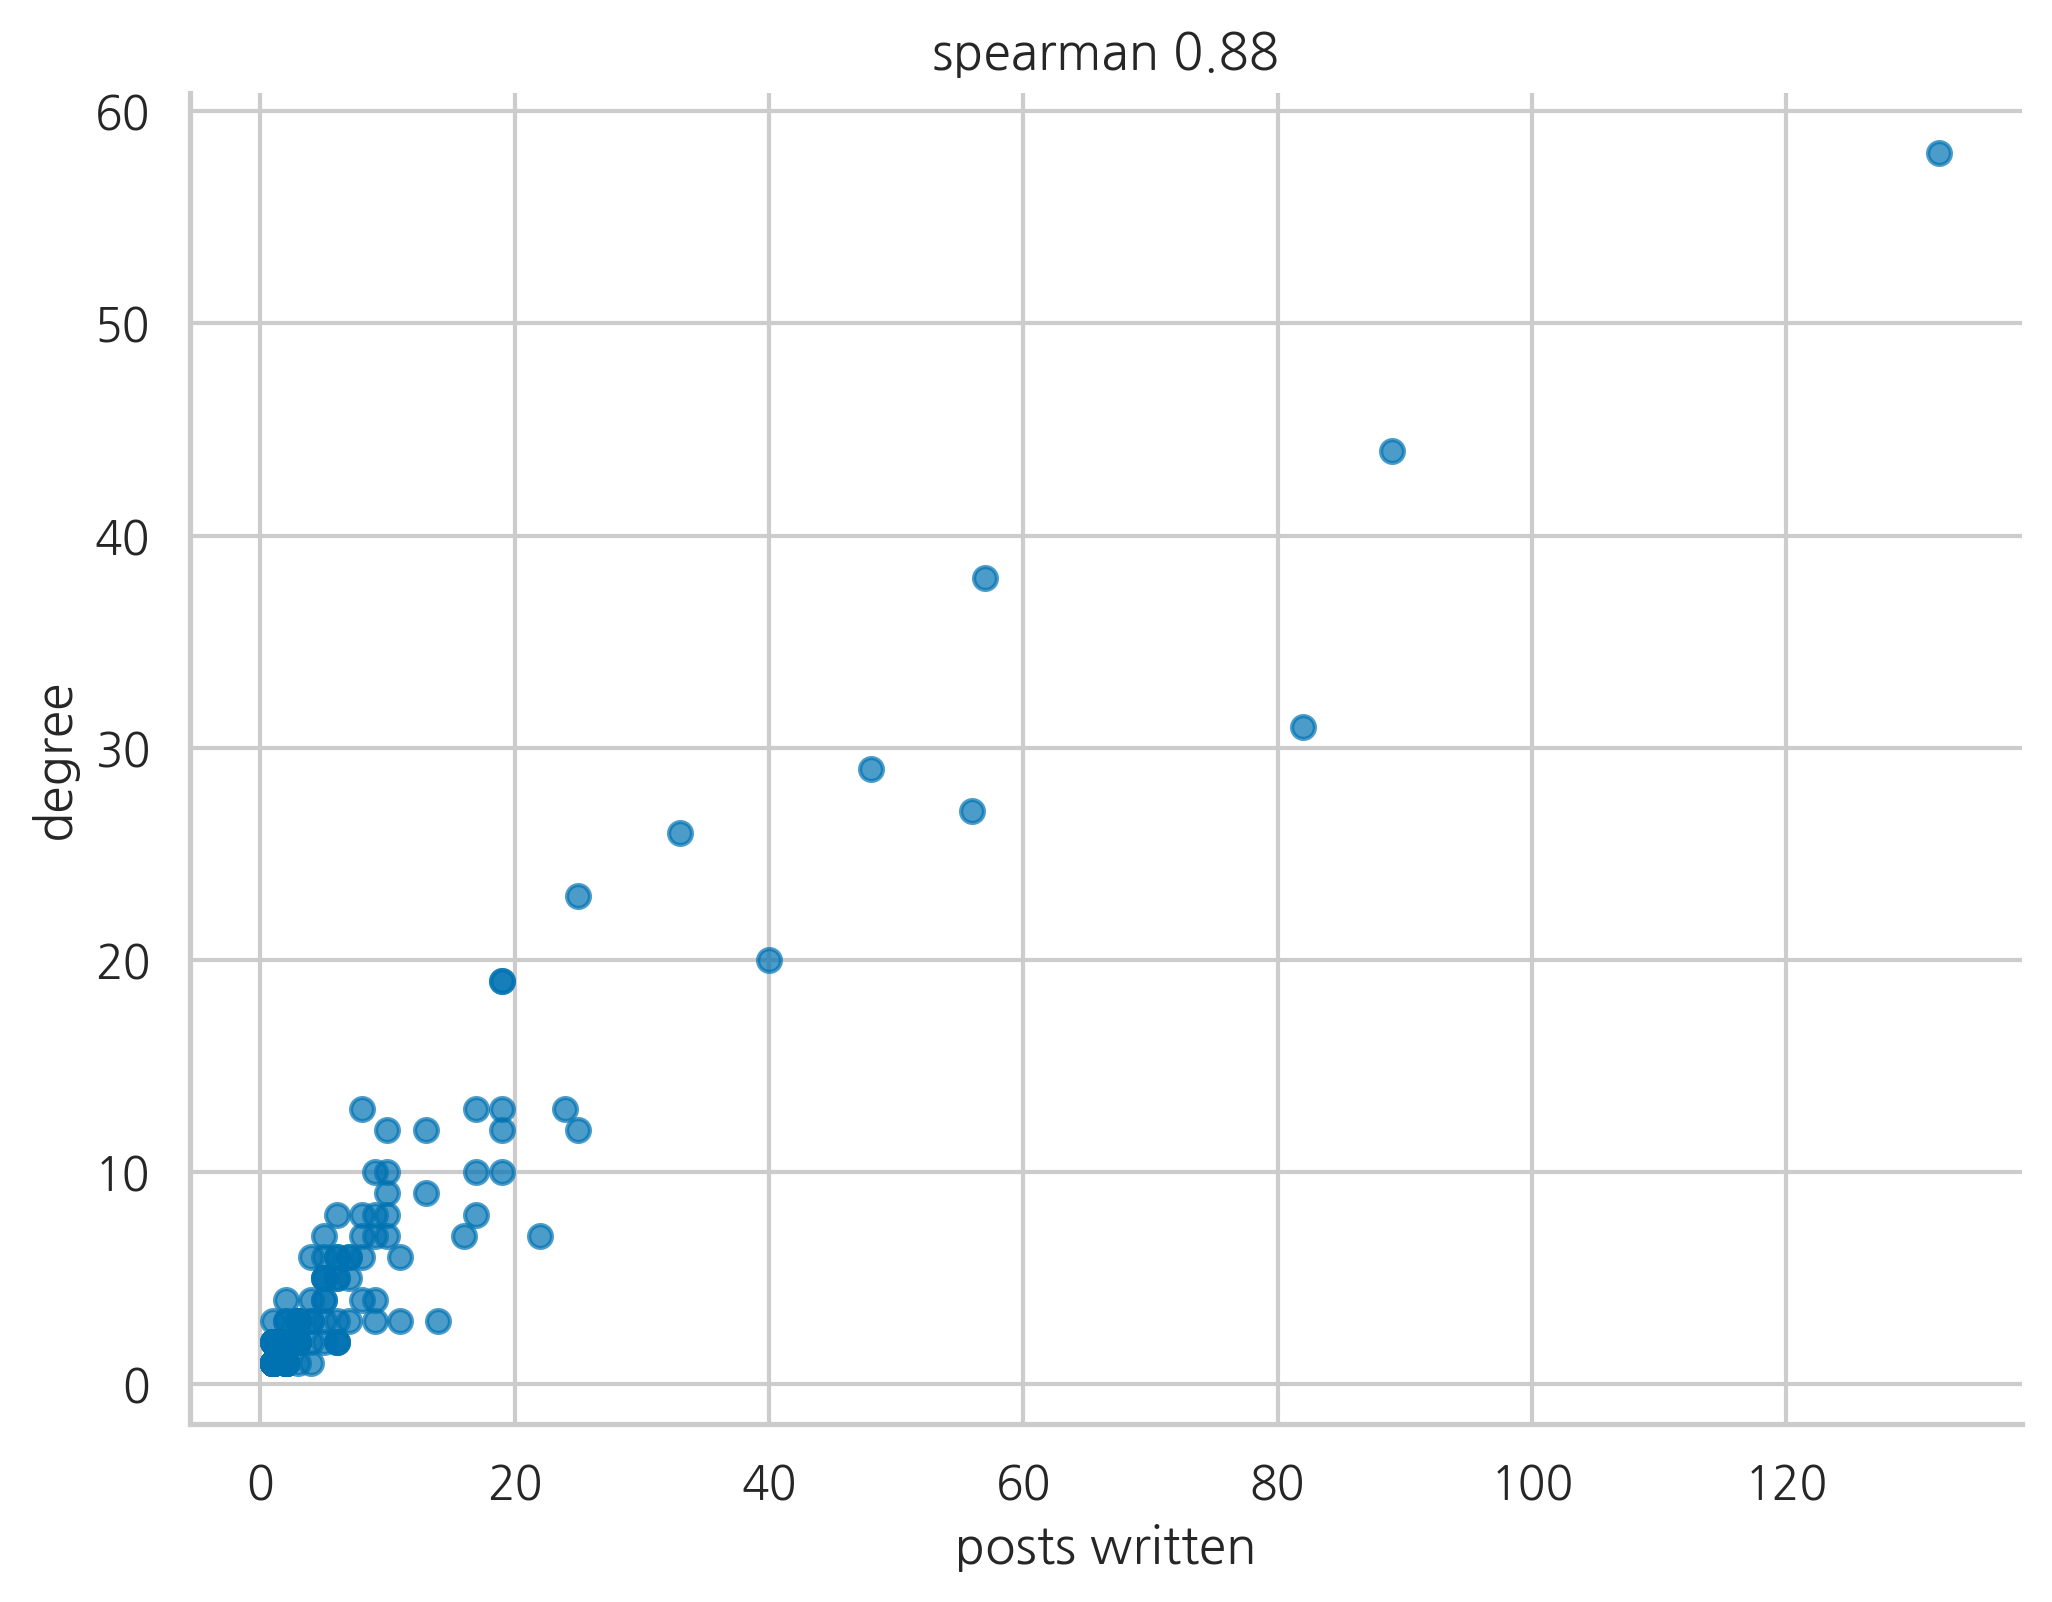

In [6]:
cent = pd.DataFrame({
    "degree": pd.Series(deg),
    "posts written": posts.author.value_counts(),
}).dropna()
cent["rank by degree"] = cent.degree.rank(ascending=False, method="min").astype(int)
cent["rank by posts"]  = cent["posts written"].rank(ascending=False, method="min").astype(int)
cent["moved"] = cent["rank by posts"] - cent["rank by degree"]

print("The top 10 by degree, and where a post count would have put them:")
display(cent.nsmallest(10, "rank by degree").reset_index(drop=True))

print("\nThe people who move most:")
display(cent.reindex(cent.moved.abs().sort_values(ascending=False).index)
            .head(8).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(cent["posts written"], cent.degree, s=30, color="#0072b2", alpha=.7)
ax.set_xlabel("posts written"); ax.set_ylabel("degree")
ax.set_title(f"spearman {cent.degree.corr(cent['posts written'], method='spearman'):.2f}", fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Takeaway**

- Degree and post count agree at 0.88, and the top 10 shift by at most 3 places. Counting posts would have produced nearly the same list.
- The people who move are at the bottom: one post, three ties.
- This is the warning in Poquet and Joksimovic, measured. Before reporting centrality, check what it adds to a count you already had.

## 6. Change the rule

`MIN_REPLIES` keeps a tie only if the two people replied to each other at least this many times.

Run it at 1, then 2, then 3. Watch how many people fall out of the picture each time, and decide at which value the network stops being about the forum.

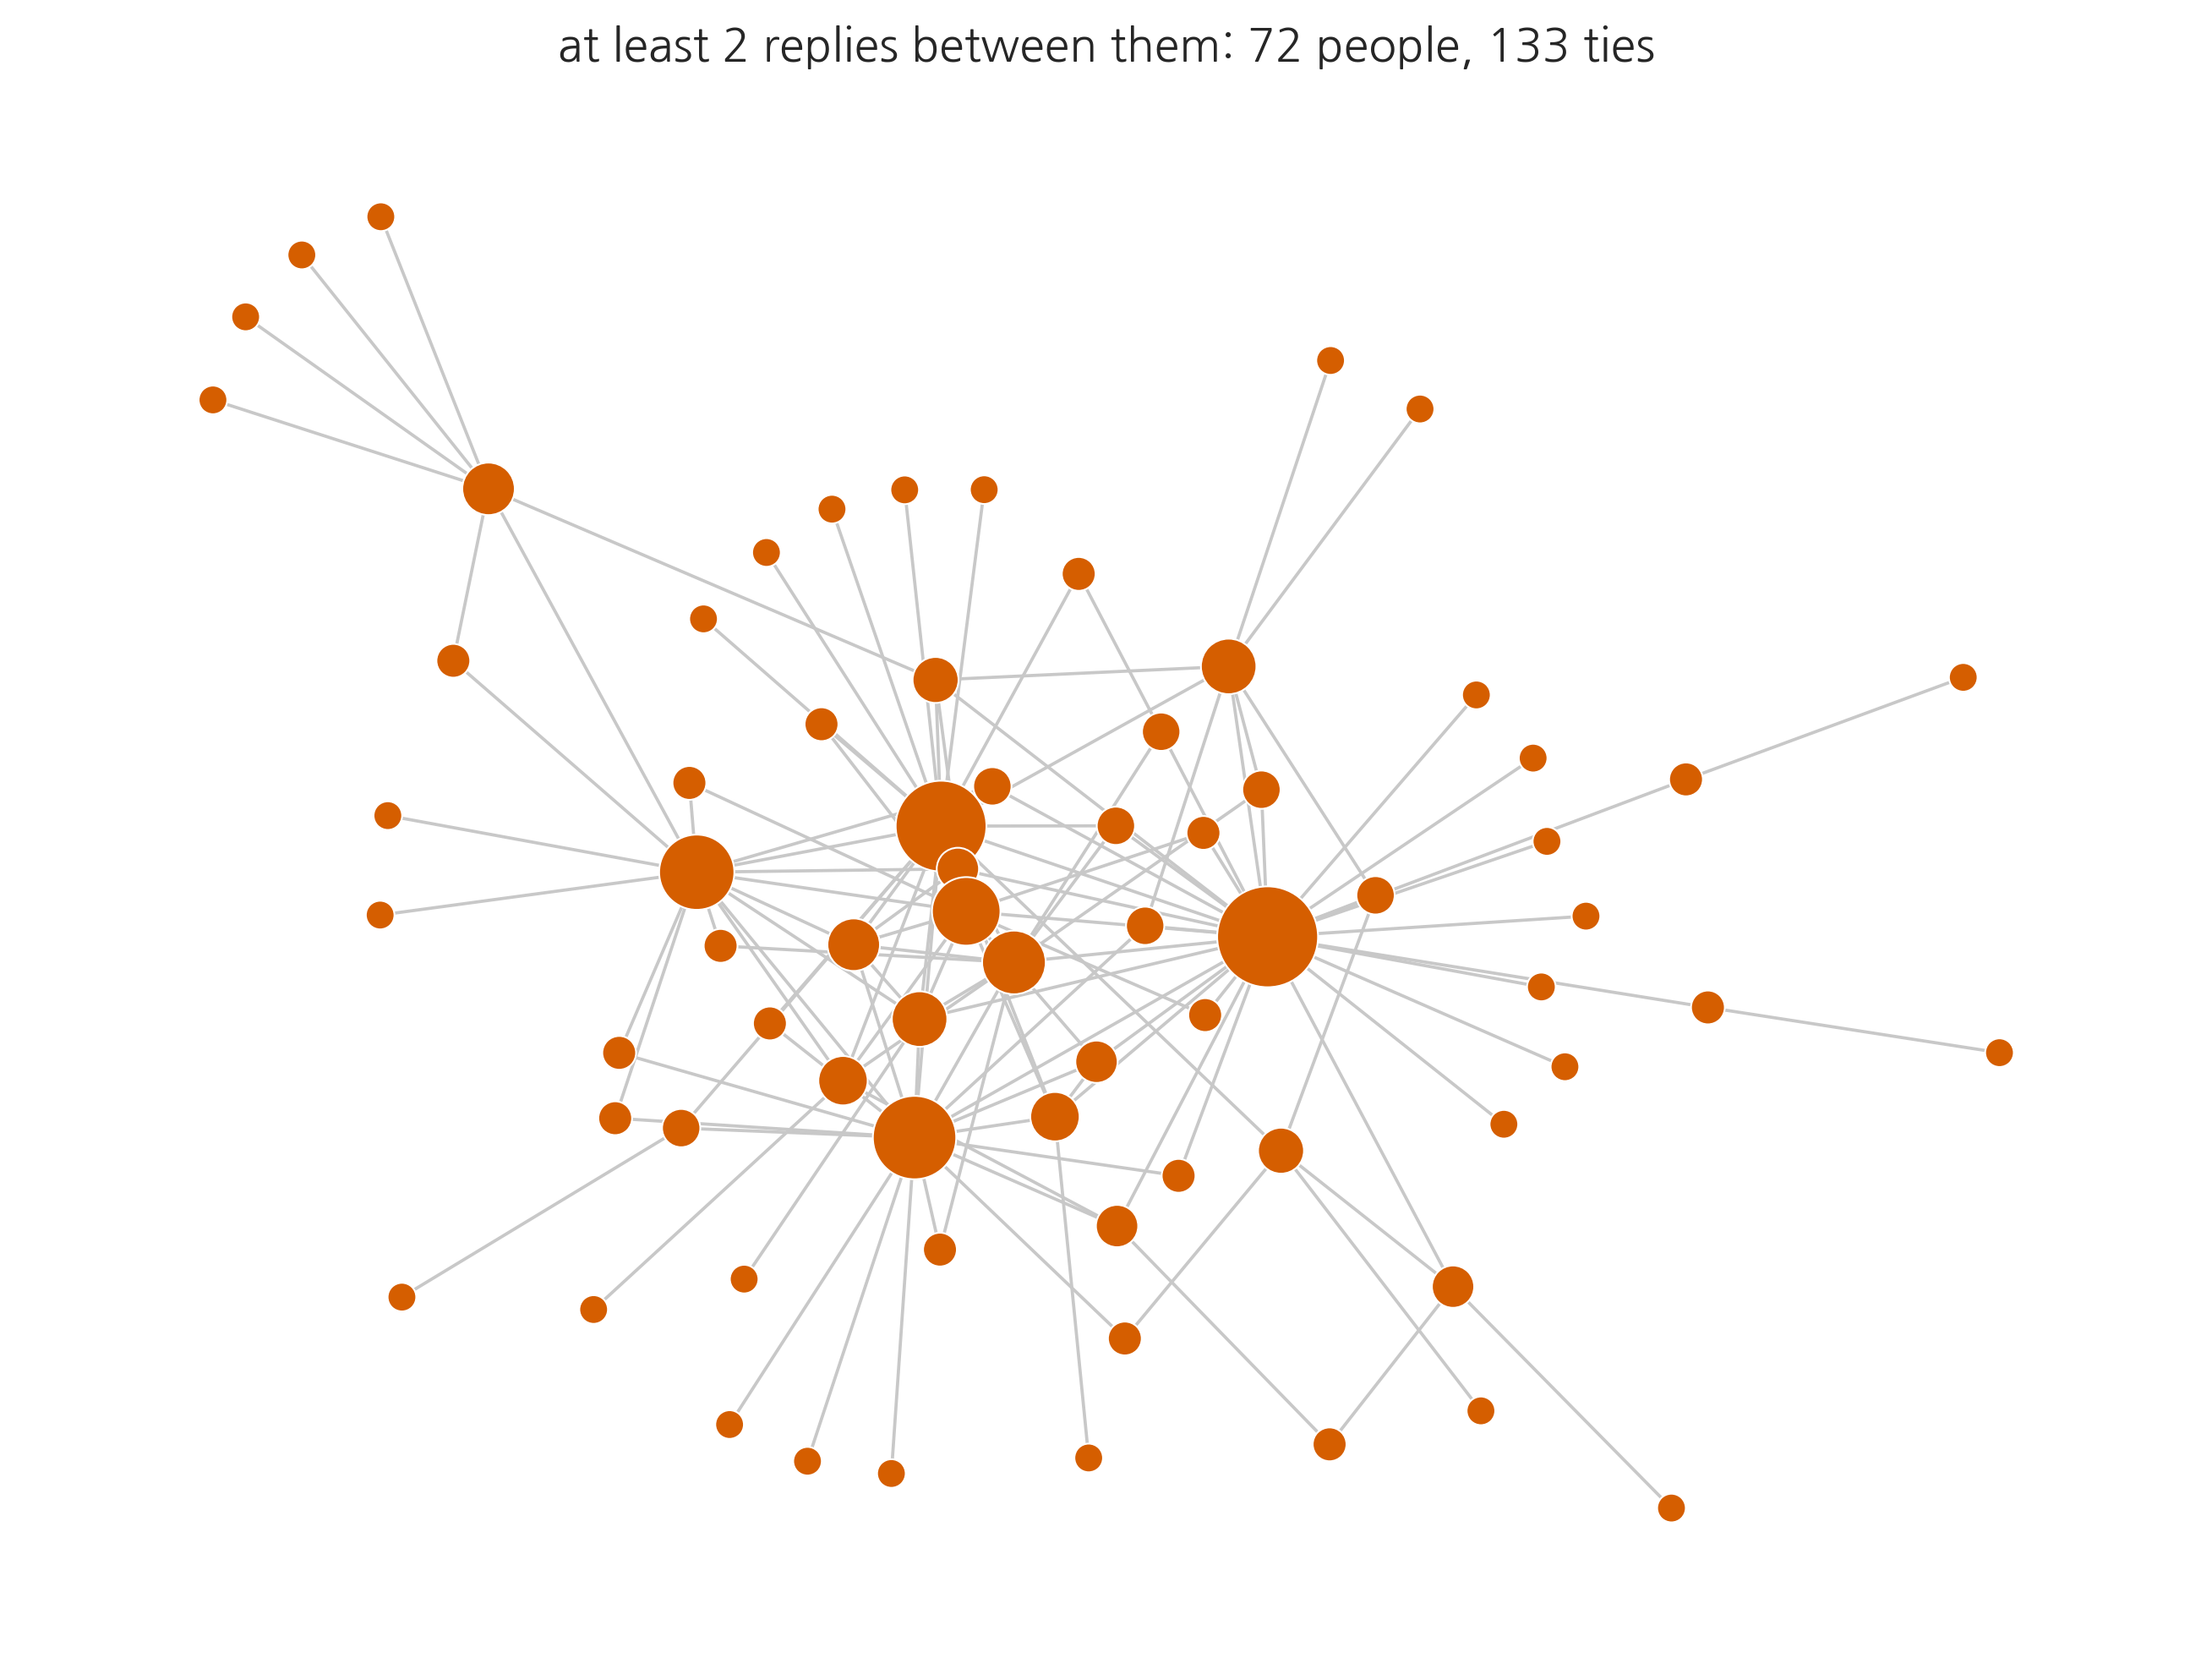

In [7]:
MIN_REPLIES = 2        # change this to 1, 2, 3 ...

counts = {}
for _, r in posts.dropna(subset=["parent_post_id"]).iterrows():
    t = author_of.get(r.parent_post_id)
    if t and t != r.author:
        k = tuple(sorted((r.author, t)))
        counts[k] = counts.get(k, 0) + 1

H = nx.Graph()
H.add_edges_from([k for k, v in counts.items() if v >= MIN_REPLIES])
K = H.subgraph(max(nx.connected_components(H), key=len)).copy() if H.number_of_edges() else H

p = nx.spring_layout(K, seed=8100, k=0.6, iterations=250)
d = dict(K.degree())
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(K, p, ax=ax, edge_color="#c8c8c8", width=0.9)
nx.draw_networkx_nodes(K, p, ax=ax, node_color="#d55e00",
                       node_size=[40 + 26 * d[n] for n in K.nodes()], edgecolors="white", linewidths=0.5)
ax.set_title(f"at least {MIN_REPLIES} replies between them: "
             f"{K.number_of_nodes()} people, {K.number_of_edges()} ties", fontsize=13)
ax.axis("off"); plt.show()

**Takeaway**

- Raising the threshold does not trim the network evenly. It removes the people who replied once, which is most of them.
- A cleaner picture and a smaller claim are the same move.
- Where you set it decides who is in the study, and nothing in the data sets it for you.

## Read the posts

Pull what one person actually wrote.

In [8]:
WHO = cent.nsmallest(1, "rank by degree").index[0]   # change to any author id

print(f"{deg[WHO]} ties, {int(cent.loc[WHO, 'posts written'])} posts\n")
for _, r in posts[posts.author == WHO].head(12).iterrows():
    print(f"[{r.category_name}] {str(r.body)[:150]}")

58 ties, 132 posts

[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] And this is what is incorrectly marked as correct:     ![failure trace error][1]     [1]: https://edxuploads.s3.amazonaws.com/14626129267029983.png
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] The wording of the question is misleading.        The expected values in the test itself are not correct → the question should read :     What are/wou
[Week 2 / Program FuelTankTest in Eclipse (non graded activity)] Thank you florina - the text is much clearer now!
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.     → Any negative input will lead to a stack overflow     → Negative inputs are lega
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.   → Any negative input will lead to a stack overflow      → Negative inputs are legal
[Week 3 / Exam 3] The accepted answer to "What are they used for?" is not correct.    → Any negati

1. Does the person with the highest degree look like the most important person in the forum?
2. The three rules in section 2 gave three different networks. What decides which one you use?
3. What happened in this forum that none of these networks can see?